# 08 · The Temporal Model and the ML + DL Hybrid
**Owner:** Rishik Chowdary Karuturi (2401010381) · Phase 2 rubric: **architecture logic**, **hybrid innovation**, **technical validation**

**Builds on:** 06 (sequences), 07 (`deep.py`, best MLP settings). **Commits:** `src/fdp/phase1_models.py`, `reports/08_temporal_hybrid.json`, `reports/figures/08_*.png`.

| Section | What it answers |
|---|---|
| A · How a GRU reads two weeks | the temporal architecture |
| B · The hybrid, and why it is justified | logistic regression + a network that learns only corrections |
| C · All models on the same rolling months | the model-selection evidence |
| D · Is the difference real? Seeds | how much of a gap is just the random start |
| E · Phase 1's models, refitted | the exact baselines notebook 10 will use |

⏱️ About 35–45 minutes on a Colab **CPU**, 10–15 on a **GPU** runtime (Runtime → Change runtime type → T4). `QUICK_RUN` ≈ 8 minutes.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/RISHIK92/aml-project.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/aml-project/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/aml-project"], check=True)
    os.chdir("/content/aml-project")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(max(1, os.cpu_count() or 1))
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /tmp/fdp | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.dl_inputs as dl, fdp.deep as deep
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
NO_HIST = [c for c in NUM if c not in groups["history"]]          # 19 numeric features without the hand-made history
S = data.split(X)
lab = pd.concat([S["train"], S["valid"]])
month = lab["date"].dt.month.to_numpy()
ylab = lab["delayed"].astype(int).to_numpy()
seq = dl.build_sequences(df, lab)
r07 = json.load(open("reports/07_mlp.json"))
BODY = {k: (tuple(v) if k == "hidden" else v) for k, v in r07["best"].items()}
MONTHS = [9] if QUICK_RUN else config.CV_MONTHS
print("network body from notebook 07:", BODY, "| sequences:", seq.shape)

network body from notebook 07: {'hidden': (256, 128), 'dropout': 0.5, 'lr': 0.0003, 'weight_decay': 0.01} | sequences: (232652, 14, 16)


---
## A · How a GRU reads two weeks
A **GRU** (gated recurrent unit; Cho et al., 2014) reads the 14 days **in order**, oldest first, keeping a hidden state $h_t$ (32 numbers) as its memory:

$$z_t = \sigma(W_z x_t + U_z h_{t-1}),\quad r_t = \sigma(W_r x_t + U_r h_{t-1})$$
$$\tilde h_t = \tanh(W x_t + U(r_t \odot h_{t-1})),\quad h_t = (1-z_t)\odot h_{t-1} + z_t \odot \tilde h_t$$

* the **update gate** $z_t$ decides how much of today's input replaces the memory;
* the **reset gate** $r_t$ decides how much old memory to use when reading today;
* the same weights are used for every day, so the model learns *how* to weigh recent vs older days instead of us fixing 1/7/28-day windows.

The last state $h_{14}$ (a summary of the two weeks) is **concatenated** with the numeric block and the embeddings, and the rest of the network is the MLP from notebook 07.

**Why a GRU and not an LSTM or a Transformer?** 14 short steps and 16 channels: a GRU has fewer weights than an LSTM (no separate cell state) and handles this length without trouble; a Transformer's strength (long-range attention) is not needed for two weeks, and its extra weights would mostly add variance on ~200k rows. Gated recurrence was introduced to fix the **vanishing gradient** of plain RNNs (Hochreiter & Schmidhuber, 1997).

---
## B · The hybrid, and why it is justified
Phase 1's strongest, most stable model was **logistic regression**: it transfers across seasons because it only rescales its inputs. The networks can learn interactions and ordered history, but their extra learning may not transfer. The hybrid gives each part the job it is good at:

$$\text{logit}(x) = \underbrace{w^\top x + b}_{\text{LR, fixed, all 41 hand-made features}} \; + \; \underbrace{g_\theta(x_{\text{no history}},\ \text{embeddings},\ \text{GRU(14 days)})}_{\text{network: learns only the correction}}$$

* LR is fitted first on the training rows; its logit enters the network as a **fixed offset**.
* The network's last layer starts at **zero**, so before training the hybrid **is** logistic regression. Early stopping also scores this "epoch 0"; if no correction transfers to the stopping month, it keeps plain LR. **The hybrid cannot be much worse than LR by construction.**
* The two parts see the data **differently**: LR reads the hand-made 1/7/28-day averages; the GRU reads the raw ordered days. That is the brief's *"operational tabular features → learned temporal patterns"*, and it is the DL version of Phase 1's boosting-from-LR hybrid.

---
## C · All models on the same rolling months
Same honest protocol as notebooks 05 and 07 (stop on m−1, refit, score m). Phase 1's XGBoost numbers come from the Phase 1 report (Table V), which used the same months and protocol.

In [3]:
from sklearn.metrics import average_precision_score as ap
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
import fdp.preprocess as prep, time
lr_scores = []
for m in MONTHS:
    tr, va = np.where(month < m)[0], np.where(month == m)[0]
    lr = make_pipeline(prep.linear_preprocessor(NUM, CAT), LogisticRegression(C=config.PHASE1_LR_C, max_iter=3000)).fit(lab.iloc[tr], ylab[tr])
    lr_scores.append(float(ap(ylab[va], lr.decision_function(lab.iloc[va]))))

CANDIDATES = {   # name: (config, network numeric columns, LR-offset columns)
    "MLP + embeddings":                    (dict(BODY),                                 NUM,     None),
    "Temporal: GRU + all features":        (dict(BODY, use_seq=True),                   NUM,     None),
    "Temporal: GRU replaces hand history": (dict(BODY, use_seq=True),                   NO_HIST, None),
    "Hybrid: LR + temporal correction":    (dict(BODY, use_seq=True, use_offset=True),  NO_HIST, NUM),
}
roll, epochs, secs = {"Logistic regression": lr_scores}, {}, {}
for name, (cfg, cols, off) in CANDIDATES.items():
    t = time.time()
    s, e = deep.rolling_eval_nn(lab, seq, month, cfg, cols, CAT, months=MONTHS, seed=config.SEED, offset_numeric=off)
    roll[name], epochs[name], secs[name] = s, e, round(time.time() - t)
    print(f"{name:38s} {np.round(s, 4)} mean {np.mean(s):.4f} epochs {e} ({secs[name]} s)", flush=True)
idx = ["Jul", "Aug", "Sep"][-len(MONTHS):]
table = pd.DataFrame(roll, index=idx).T
table["mean"] = table.mean(axis=1)
if not QUICK_RUN:
    table.loc["XGBoost, tuned (Phase 1 report)"] = [0.548, 0.391, 0.219, 0.386]
    table.loc["Hybrid: XGBoost from LR (Phase 1 report)"] = [0.559, 0.391, 0.268, 0.406]
table.round(4)

MLP + embeddings                       [0.5598 0.4036 0.2553] mean 0.4062 epochs [6, 8, 2] (68 s)


Temporal: GRU + all features           [0.5635 0.4029 0.2593] mean 0.4086 epochs [8, 7, 2] (169 s)


Temporal: GRU replaces hand history    [0.5652 0.4047 0.2633] mean 0.4111 epochs [16, 19, 11] (390 s)


Hybrid: LR + temporal correction       [0.5658 0.4102 0.2704] mean 0.4155 epochs [11, 15, 11] (340 s)


,Jul,Aug,Sep,mean
Logistic regression,0.5565,0.4055,0.2655,0.4092
MLP + embeddings,0.5598,0.4036,0.2553,0.4062
Temporal: GRU + all features,0.5635,0.4029,0.2593,0.4086
Temporal: GRU replaces hand history,0.5652,0.4047,0.2633,0.4111
Hybrid: LR + temporal correction,0.5658,0.4102,0.2704,0.4155
"XGBoost, tuned (Phase 1 report)",0.5480,0.3910,0.2190,0.3860
Hybrid: XGBoost from LR (Phase 1 report),0.5590,0.3910,0.2680,0.4060


**What to look for:**
* Do the networks beat **logistic regression's** rolling mean, and by how much compared with the seed spread in section D?
* **"GRU replaces hand history"** has *no* hand-made history features at all. If it matches the models that have them, the network has **learned** from the raw ordered days what we engineered by hand in Phase 1. That is the gap the brief names, tested directly.
* The **epoch counts** per fold: small and jumpy means little of the extra learning transfers from one month to the next.

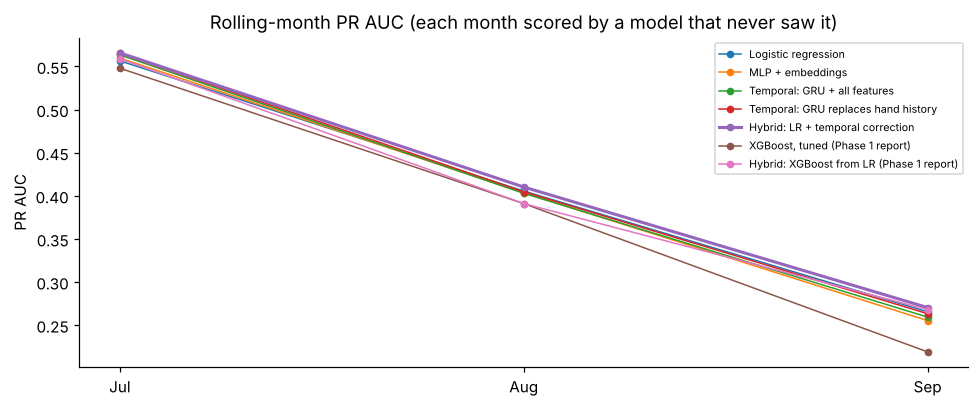

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
t2 = table.drop(columns="mean")
for name in t2.index:
    ax.plot(t2.columns, t2.loc[name], "o-", ms=4, label=name, lw=2 if name.startswith("Hybrid: LR") else 1)
ax.set(title="Rolling-month PR AUC (each month scored by a model that never saw it)", ylabel="PR AUC"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("reports/figures/08_rolling.png"); plt.show()

---
## D · Is the difference real? Seeds
A network starts from random weights and sees mini-batches in a random order. Re-running with another **seed** changes the score a little. If two models differ by less than this seed-to-seed spread, the ranking is noise.

In [5]:
#@title 🎛️ Extra seeds { display-mode: "form" }
EXTRA_SEEDS = "1,2"  #@param {type:"string"}
seeds = [int(s) for s in EXTRA_SEEDS.split(",") if s.strip()]
if QUICK_RUN:
    seeds = []
spread = []
for name in ["MLP + embeddings", "Temporal: GRU replaces hand history", "Hybrid: LR + temporal correction"]:
    cfg, cols, off = CANDIDATES[name]
    means = [float(np.mean(roll[name]))]
    for sd in seeds:
        s, _ = deep.rolling_eval_nn(lab, seq, month, cfg, cols, CAT, months=MONTHS, seed=sd, offset_numeric=off)
        means.append(float(np.mean(s)))
        print(name, "seed", sd, np.round(s, 4), flush=True)
    spread.append({"model": name, "seeds": [config.SEED] + seeds, "rolling means": [round(v, 4) for v in means],
                   "mean over seeds": float(np.mean(means)), "min": min(means), "max": max(means), "range": max(means) - min(means)})
spread = pd.DataFrame(spread).set_index("model")
print("logistic regression (no randomness):", round(float(np.mean(lr_scores)), 4))
spread.round(4)

MLP + embeddings seed 1 [0.5603 0.405  0.2583]


MLP + embeddings seed 2 [0.5591 0.4028 0.2608]


Temporal: GRU replaces hand history seed 1 [0.5629 0.404  0.2648]


Temporal: GRU replaces hand history seed 2 [0.5607 0.4036 0.2598]


Hybrid: LR + temporal correction seed 1 [0.563  0.4105 0.2693]


Hybrid: LR + temporal correction seed 2 [0.5641 0.4081 0.2673]


logistic regression (no randomness): 0.4092


,seeds,rolling means,mean over seeds,min,max,range
model,,,,,,
MLP + embeddings,"[42, 1, 2]","[0.4062, 0.4079, 0.4076]",0.4072,0.4062,0.4079,0.0017
Temporal: GRU replaces hand history,"[42, 1, 2]","[0.4111, 0.4106, 0.4081]",0.4099,0.4081,0.4111,0.0030
Hybrid: LR + temporal correction,"[42, 1, 2]","[0.4155, 0.4142, 0.4132]",0.4143,0.4132,0.4155,0.0023


**The decision rule, fixed before the test months:** the three networks above all go to the final exam in notebook 10, next to Phase 1's three models. This table is our **expectation**: a network counts as ahead of logistic regression on the rolling months only if *every* seed is above LR's mean; otherwise the gap is seed noise. The test months may still behave differently from Jul–Sep, so whatever the test says, we report it next to this table.

---
## E · Phase 1's models, refitted with the reported settings
Notebook 10 compares the networks with **exactly** the Phase 1 models: same C, same XGBoost settings and tree counts (copied into `config.py` from the Phase 1 report), refitted on the same rows. `phase1_models.py` wraps them so notebook 10 is short.

In [6]:
%%writefile src/fdp/phase1_models.py
"""Phase 2 · Phase 1's three final models, refitted with the settings we reported.
Owner: Rishik Chowdary Karuturi (Rishik).

Phase 2 must compare against EXACTLY what Phase 1 reported, on the same rows, in the same run:
  logistic regression  C = 0.001
  XGBoost              tuned settings, 40 trees
  hybrid               XGBoost starting from LR's logit (base_margin), 16 trees
(the settings live in config.py, copied from the Phase 1 report).
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from . import config
from .boosting import as_xgb_frame, make_xgb
from .preprocess import linear_preprocessor


class Phase1Models:
    def __init__(self, numeric, categorical, categories: dict):
        self.num, self.cat, self.cats = list(numeric), list(categorical), categories

    def fit(self, frame: pd.DataFrame):
        y = frame["delayed"].astype(int).to_numpy()
        self.lr = make_pipeline(linear_preprocessor(self.num, self.cat),
                                LogisticRegression(C=config.PHASE1_LR_C, max_iter=3000)).fit(frame[self.num + self.cat], y)
        F = as_xgb_frame(frame, self.num, self.cat, self.cats)
        self.xgb = make_xgb(config.PHASE1_XGB, config.PHASE1_XGB_TREES, config.SEED).fit(F, y)
        self.hyb = make_xgb(config.PHASE1_XGB, config.PHASE1_HYBRID_TREES, config.SEED).fit(
            F, y, base_margin=self.lr.decision_function(frame[self.num + self.cat]))
        return self

    def logits(self, frame: pd.DataFrame) -> dict:
        """Scores on the logit scale (what calibration expects)."""
        F = as_xgb_frame(frame, self.num, self.cat, self.cats)
        lr_logit = self.lr.decision_function(frame[self.num + self.cat])
        return {"Logistic regression": lr_logit,
                "XGBoost (Phase 1)": self.xgb.predict(F, output_margin=True),
                "Hybrid: XGBoost from LR (Phase 1)": self.hyb.predict(F, base_margin=lr_logit, output_margin=True)}

    def lr_logit(self, frame: pd.DataFrame) -> np.ndarray:
        return self.lr.decision_function(frame[self.num + self.cat])

Overwriting src/fdp/phase1_models.py


In [7]:
import fdp.phase1_models as p1; importlib.reload(p1)
CATS = {c: sorted(X[c].astype(str).unique()) for c in CAT}
ref = p1.Phase1Models(NUM, CAT, CATS).fit(S["train"])
oct_scores = {k: round(float(ap(S["calib"]["delayed"].astype(int), v)), 4) for k, v in ref.logits(S["calib"]).items()}
print("trained on Jan 15 – Aug, October PR AUC:", oct_scores)

trained on Jan 15 – Aug, October PR AUC: {'Logistic regression': 0.3079, 'XGBoost (Phase 1)': 0.2731, 'Hybrid: XGBoost from LR (Phase 1)': 0.2921}


In [8]:
out = {"body": {k: (list(v) if isinstance(v, tuple) else v) for k, v in BODY.items()}, "months": MONTHS,
       "rolling": table.reset_index().rename(columns={"index": "model"}).to_dict(orient="records"),
       "epochs_per_fold": epochs, "seconds": secs, "seed_spread": spread.reset_index().to_dict(orient="records"),
       "lr_rolling_mean": float(np.mean(lr_scores)), "phase1_october_check": oct_scores,
       "candidates": {k: {"config": {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in v[0].items()},
                          "numeric": "no_history" if v[1] is NO_HIST else "all", "offset": v[2] is not None} for k, v in CANDIDATES.items()},
       "quick_run": QUICK_RUN}
with open("reports/08_temporal_hybrid.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/08_temporal_hybrid.json")

saved reports/08_temporal_hybrid.json


<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **What do the update and reset gates do?** Update: how much of the memory is replaced by today's information. Reset: how much past memory is used when reading today. Both are learned sigmoids between 0 and 1.
2. **Why a recurrent model at all, when Phase 1 had 1/7/28-day averages?** Averages fix the windows and lose the order of days. The GRU learns its own weighting of the 14 days and can react to patterns like "bad yesterday after a calm week".
3. **Why GRU over LSTM / Transformer?** Short sequences (14), few channels (16), ~200k rows: a GRU has fewer weights than an LSTM and is enough for 14 steps; attention's long-range strength is not needed and adds variance.
4. **Explain the hybrid in one sentence.** Logistic regression on the hand-made features gives the starting logit; a temporal network on raw ordered history learns only the correction, starting from zero.
5. **Why is it "technically justified" and not just stacking?** Each part has a reason: LR is the most season-stable model (Phase 1); the network adds what LR cannot represent (interactions, ordered history). Zero-init + epoch-0 early stopping guarantee it starts as, and can fall back to, LR.
6. **What does "GRU replaces hand history" prove?** With none of the 22 hand-made history features, the network reaches the same level from raw days: the learned representation recovers what we engineered.
7. **Why report seed spread?** A network's score moves with the random start. A gap smaller than the seed range is not evidence that one model is better.
8. **Why refit Phase 1's models here instead of copying their test scores?** The comparison must be the same rows, same run, same code path; copying numbers from another run invites small mismatches.
</details>

In [9]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them as shown in the team guide.
import glob, zipfile
FILES = [
    'src/fdp/phase1_models.py',
    'reports/08_temporal_hybrid.json',
    'reports/figures/08_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "08_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 3 files into 08_outputs.zip
   reports/08_temporal_hybrid.json
   reports/figures/08_rolling.png
   src/fdp/phase1_models.py
